<a href="https://colab.research.google.com/github/Endoefa/ovo/blob/main/Tutorial_Three.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## UFMFRR-15-M - Machine Vision Tutorial

# Unit 3 - Dataset Management



---



## Mount Google Drive to Google Colab

Mounting Google Drive to Google Colab offers several practical advantages, especially for data science, machine learning, and  research workflows. Here are the key benefits:

**Persistent Storage:** Files saved to Drive remain available across Colab sessions, unlike temporary local storage.

**Access to Large Files:** Easily work with large datasets or models stored in Drive without repeated uploads.

**Convenient File I/O:** Read and write files directly using familiar Python file operations.

Please run the following code. This will prompt you to authenticate and grant permissions for Google Colab to access your Google Drive.

将Google Drive安装到Google Colab上，尤其对数据科学、机器学习和研究工作流程有诸多实际优势。以下是主要优势：

持久存储：存储到驱动器的文件会在 Colab 会话间保持可用，这与临时本地存储不同。

访问大文件：轻松处理存储在 Drive 中的大型数据集或模型，无需重复上传。

便捷的文件输入输出：使用熟悉的Python文件操作直接读写文件。

请运行以下代码。这会提示您验证并授权Google Colab访问您的Google Drive。

In [26]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


After successfully mounting, you can navigate to /content/drive/My Drive in the file browser on the left to access your files.


---



## Read a sample dataset provided by Colab
The MNIST dataset is a widely used benchmark in machine learning, consisting of handwritten digits from 0 to 9, captured in various fonts and styles. In this chapter, we will visualize a subset of these images using the file located at "/content/sample_data/mnist_test.csv".
阅读Colab提供的示例数据集

MNIST 数据集是机器学习中广泛使用的基准测试，由手写数字 0 到 9 组成，采用多种字体和风格捕捉。本章将使用位于“/content/sample_data/mnist_test.csv”的文件，可视化这些图像的子集。

In [27]:
import pandas as pd
df_mnist = pd.read_csv('/content/sample_data/mnist_test.csv')

Separate the labels from the pixel data and reshape the pixel data into 28x28  images.

In [28]:
# df_mnist: MNIST数据集DataFrame，第0列是数字标签，后面784列对应28*28图像像素
# 选取所有行，第0列，得到手写数字标签向量
labels = df_mnist.iloc[:, 0]

# iloc[:, 1:] 选取所有行，第1列到最后一列（全部像素值）
# .values 将pandas Series/DataFrame转为numpy数组
# reshape(-1,28,28)：把一维784像素向量，还原成28行28列的二维图像矩阵
# -1 代表自动计算样本总数，无需手动指定
images = df_mnist.iloc[:, 1:].values.reshape(-1, 28, 28)


Display the first 25 images using matplotlib.




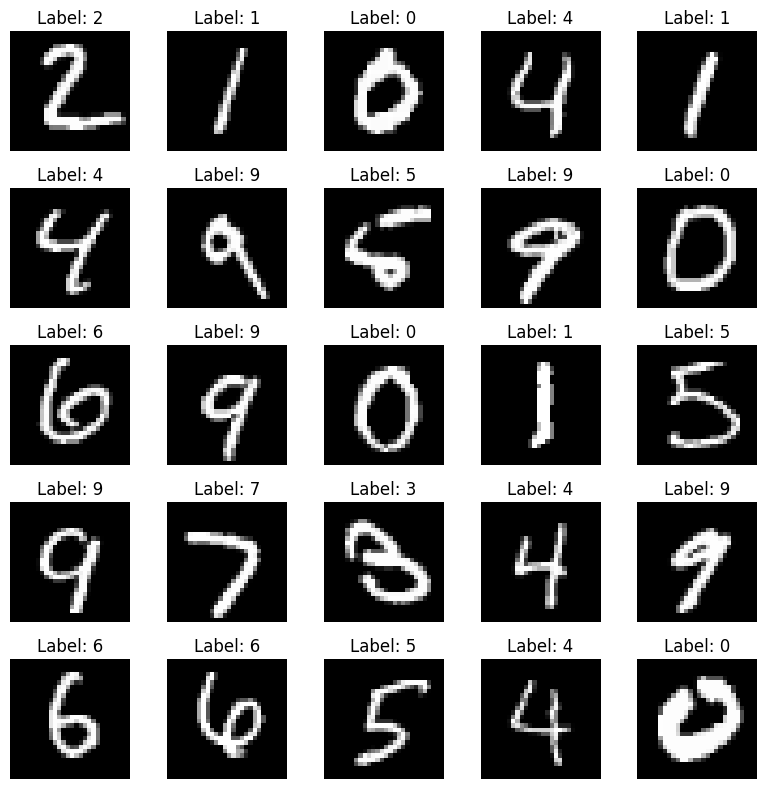

In [29]:
import matplotlib.pyplot as plt

# 创建画布与子图网格：5行5列共25张子图，画布大小8×8英寸
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
# 将二维axes数组展平为一维数组，方便用索引循环访问每个子图
axes = axes.flatten()

# 循环遍历前25张图像
for i in range(25):
    # 在第i个子图上绘制灰度图像
    axes[i].imshow(images[i], cmap='gray')
    # 设置子图标题，显示该图像对应的真实标签
    axes[i].set_title(f'Label: {labels[i]}')
    # 关闭子图坐标轴，只保留图片
    axes[i].axis('off')

# 自动调整子图间距，防止标题重叠
plt.tight_layout()
# 弹出窗口展示绘图结果
plt.show()


---
## Creating an image dataset with labels

Save 100 images from the `images` array as pseudo-colored PNG files in the directory "/content/sample_data/MyImageDataset/" (change this to your Google drive if want to keep the images after this session). Create a CSV file named "labels.csv" in the same directory with columns "split", "label", and "image_path" for these 100 images, i.e.,



```
TRAIN,2,image_043.png
```



The first 80 images should have "split" as "TRAIN" and the remaining 20 as "TEST". The "label" column should contain the corresponding label from the `labels` array, and the "image_path" column should contain the path to the saved image file.

First, create the directory using the `os` module if it doesn't exist.

## 创建带标签的图像数据集

将`images`数组中的100张图像保存为伪彩色PNG文件，存放至目录`/content/sample_data/MyImageDataset/`（如果需要在本次会话结束后保留图像，请将路径修改为你的谷歌云盘路径）。在同一目录下创建名为`labels.csv`的CSV文件，该文件包含`split`、`label`和`image_path`三列，用于记录这100张图像，示例如下：

```
TRAIN,2,image_043.png
```

前80张图像的`split`字段值设为`TRAIN`，剩余20张设为`TEST`。`label`列填写`labels`数组中对应的标签，`image_path`列填写保存的图像文件路径。

首先，使用`os`模块创建目录（若该目录不存在）。

In [30]:
import os

# 设置保存图片的目标路径
target_dir = "/content/sample_data/MyImageDataset/"
# 创建目录，已存在则跳过
os.makedirs(target_dir, exist_ok=True)

Iterate through 100 images in the `images` array, apply a colormap to create a pseudo-colored image, and save each image as a PNG file in the created directory.
在图像数组中遍历100张图片，应用色彩映射创建一个伪彩色图像，并将每张图片保存为PNG文件，存放在创建的目录中。


In [31]:
import matplotlib.cm as cm
import matplotlib.pyplot as plt

# 循环处理前100张图像
for i in range(100):
    # 对图像应用颜色映射，生成伪彩色图像
    colored_image = cm.viridis(images[i])

    # 拼接完整文件路径，文件名格式：image_000.png、image_001.png … image_099.png
    image_path = os.path.join(target_dir, f'image_{i:03d}.png')

    # 将伪彩色图像保存为PNG文件
    plt.imsave(image_path, colored_image)

Generate a list of dictionaries or a pandas DataFrame containing the split (TRAIN/TEST), label, and image path for each of the 100 images.
生成一个词典列表或一个包含100张图像中每个的拆分（TRAIN/TEST）、标签和图像路径的pandas DataFrame。

In [32]:
image_data = []

# 遍历前100张图片，构建数据集元信息列表
for i in range(100):
    # 前80张划分训练集TRAIN，后20张划分测试集TEST
    split = "TRAIN" if i < 80 else "TEST"
    # 获取当前图片对应的标签
    label = labels[i]
    # 拼接图片完整保存路径
    image_path = os.path.join(target_dir, f'image_{i:03d}.png')
    # 将单条样本信息以字典形式加入列表
    image_data.append({"split": split, "label": label, "image_path": image_path})

# 将列表转为Pandas DataFrame
df_image_data = pd.DataFrame(image_data)

**Save** the generated data to a CSV file named `labels.csv` in the same directory.
将生成的数据保存到同一个目录中的名为“labels.csv”的CSV文件中。


In [33]:
csv_path = os.path.join(target_dir, "labels.csv")
df_image_data.to_csv(csv_path, index=False)
# 拼接labels.csv文件完整保存路径
csv_path = os.path.join(target_dir, "labels.csv")
# 将DataFrame保存为csv文件，index=False：不导出pandas自带行索引
df_image_data.to_csv(csv_path, index=False)

Now you can preview the saved images and label file in the file explorer "/content/sample_data/MyImageDataset/"

---

现在你可以在文件资源管理器中预览保存的图片和标签文件“/content/sample_data/MyImageDataset/”

## Extension: managing the dataset with TensorFlow's Dataset API

Read images from our previouly created dataset, apply horizontal flip to some images randomly and expand images to 32*32 before converting them to tensors.

扩展：使用TensorFlow的数据集API管理数据集

读取我们之前创建的数据集中的图像，对部分图像随机应用水平翻转，然后展开到32×32，然后再转换为张量。

In [34]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt

# 指定标签csv文件路径
csv_path = "/content/sample_data/MyImageDataset/labels.csv"
# 读取csv到DataFrame
df_labels = pd.read_csv(csv_path)


Select the required columns from the DataFrame and create a TensorFlow dataset from them.
从DataFrame中选择所需的列，并从中创建TensorFlow数据集。


In [35]:
# 用图片路径和标签构建tf数据集
dataset = tf.data.Dataset.from_tensor_slices((df_labels['image_path'], df_labels['label']))


Define the preprocessing function that reads the image, applies random horizontal flip and padding, and returns the processed image and label.
定义读取图像、应用随机水平翻转和填充，并返回处理后的图像和标签的预处理函数。



In [36]:
def preprocess_image(image_path, label):
    # Read the image file
    # 读取指定路径下的PNG图像原始二进制数据
    image = tf.io.read_file(image_path)
    # Decode the image
    # 解码PNG文件，设置channels=3，输出RGB三通道彩色图像
    image = tf.image.decode_png(image, channels=3)
    # Convert to float32
    # 将图像像素值归一化转换为float32浮点类型，取值范围 [0,1]
    image = tf.image.convert_image_dtype(image, dtype=tf.float32)

    # Apply horizontal flip
    # 随机水平翻转图像（数据增强，用于扩充数据集）
    image = tf.image.random_flip_left_right(image)

    # Pad the image to 32x32
    # 将28×28图像填充到32×32尺寸
    current_height = tf.shape(image)[0] # 获取图像当前高度
    current_width = tf.shape(image)[1]  # 获取图像当前宽度
    target_size = 32                    # 目标图像尺寸32×32

    pad_height = target_size - current_height # 需要在高度方向填充的总像素
    pad_width = target_size - current_width   # 需要在宽度方向填充的总像素

    # Calculate padding amounts for top, bottom, left, and right
    # 计算上下左右四个方向各自需要填充的像素数量
    pad_top = pad_height // 2
    pad_bottom = pad_height - pad_top
    pad_left = pad_width // 2
    pad_right = pad_width - pad_left

    paddings = [[pad_top, pad_bottom], [pad_left, pad_right], [0, 0]]
    # 执行填充：CONSTANT常量填充，填充像素值设为0.5（灰色），通道维度不填充
    image = tf.pad(image, paddings, "CONSTANT", constant_values = 0.5)

    return image, label

# Apply the preprocessing function to the dataset using the `map()` method.
# 使用map函数，将上面定义的预处理函数逐个应用到数据集的每一条样本
processed_dataset = dataset.map(preprocess_image)


Display a batch of images and their labels from the batched dataset to verify the preprocessing steps.
显示一批来自批量数据集的图片及其标签，以验证预处理步骤。


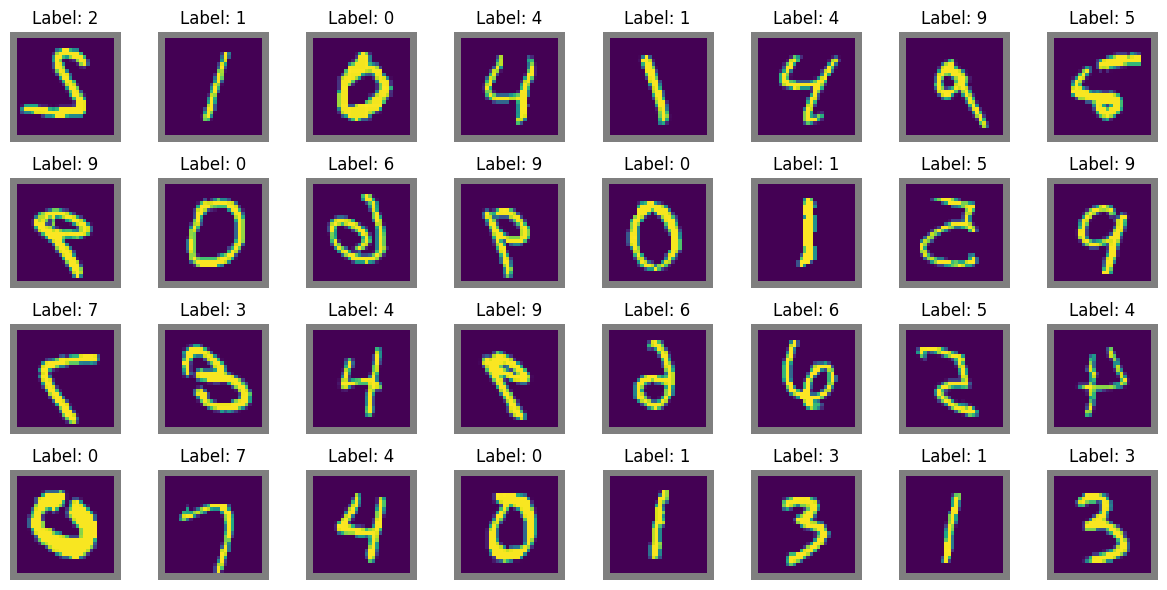

In [37]:
batch_size = 32
# 将预处理后的数据集按32个样本为一组打包成批次；prefetch提前预加载数据，AUTOTUNE自动优化预加载缓冲区
batched_dataset = processed_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# 取出1个批次的数据用于可视化
for images, labels in batched_dataset.take(1):
    # 创建4行8列的子图画布，总共可容纳32张图，画布尺寸12×6英寸
    fig, axes = plt.subplots(4, 8, figsize=(12, 6)) # Adjusted for 32 images
    # 将二维子图数组展平为一维数组，方便索引遍历
    axes = axes.flatten()

    # 遍历批次内图像，min防止图像数量不足时报错
    for i in range(min(batch_size, len(images))): # Ensure we don't exceed the number of images in the batch
        axes[i].imshow(images[i]) # imshow can handle float32 pseudo-colored images
        # Tensor标签转为numpy数值，设置子图标题显示标签
        axes[i].set_title(f'Label: {labels[i].numpy()}') # Convert tensor label to numpy for display
        axes[i].axis('off') # 隐藏坐标轴

    plt.tight_layout() # 自动调整子图间距，避免标题重叠
    plt.show() # 绘制展示图像
